# MLGuard: Dataset and Model Audit Copilot




In [47]:
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from pandas.api.types import is_numeric_dtype, is_integer_dtype

warnings.filterwarnings("ignore")  
sns.set_theme(style="whitegrid")

In [48]:
def load_data(name):
    """Return (dataframe, target_column) for a dataset name."""
    if name == "titanic":
        return sns.load_dataset("titanic"), "survived"      

    if name == "telco":
       
        for path in ["../data/telco_churn.csv", "data/telco_churn.csv", "telco_churn.csv"]:
            try:
                return pd.read_csv(path), "Churn"
            except FileNotFoundError:
                continue
        raise FileNotFoundError("telco_churn.csv not found. Put it in the data folder.")

    if name == "diabetes":
        return load_diabetes(as_frame=True).frame, "target"  

    raise ValueError("Unknown dataset: " + name)

In [49]:
datasets = {name: load_data(name) for name in ["titanic", "telco", "diabetes"]}

for name, (data, target) in datasets.items():
    print(f"{name:9s} rows={data.shape[0]:5d}  columns={data.shape[1]:3d}  target={target}")

titanic   rows=  891  columns= 15  target=survived
telco     rows= 7043  columns= 21  target=Churn
diabetes  rows=  442  columns= 11  target=target


##  Detecting the Task (Classification or Regression)




In [50]:
def detect_task(data, target_col):
    
    s = data[target_col]

   
    if not is_numeric_dtype(s):
        return "Classification"
    if s.nunique() < 15:
        return "Classification"
    return "Regression"

for name, (data, target) in datasets.items():
    print(name, "->", detect_task(data, target))

titanic -> Classification
telco -> Classification
diabetes -> Regression


##  Data Quality Check


In [51]:
def audit_quality(df):
    """Check missing values, duplicates, constant columns and wrong data types."""
    data = df.copy()                       # work on a copy, never on the original
    report = {}
    n_rows = len(data)

    # 1. Missing values (count and percent)
    missing = data.isnull().sum()
    missing = missing[missing > 0]
    report["missing"] = missing.to_dict()
    report["missing_percent"] = (missing / n_rows * 100).round(2).to_dict()

    # 2. Duplicate rows
    report["duplicates"] = int(data.duplicated().sum())

    # 3. Constant columns: only one unique value
    report["constant_cols"] = [c for c in data.columns if data[c].nunique() <= 1]

    # 4. Wrong data types: text column where more than 80% values can become numbers
    wrong = []
    for col in data.columns:
        if not is_numeric_dtype(data[col]):
            converted = pd.to_numeric(data[col], errors="coerce")   # bad values become NaN
            original_count = data[col].notnull().sum()
            if original_count > 0 and converted.notnull().sum() / original_count > 0.8:
                wrong.append(col)
    report["wrong_dtypes"] = wrong

    return report

Outlier Check (IQR Method)


In [52]:
def check_outliers(df, target_col):
    """Count outliers in each numeric feature using the IQR rule."""
    result = {}
    for col in df.select_dtypes(include="number").columns:
        if col == target_col:
            continue
        s = df[col].dropna()

        if s.nunique() <= 2:               # skip 0/1 columns, outliers make no sense there
            continue

        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        if iqr == 0:
            continue

        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((s < lower) | (s > upper)).sum())
        if n_out > 0:
            result[col] = {"count": n_out, "percent": round(n_out / len(s) * 100, 2)}
    return result

##  Class Imbalance Check


In [53]:
def check_imbalance(df, target_col, task):
    """For classification: check how small the smallest class is."""
    if task != "Classification":
        return {"applicable": False}

    percent = (df[target_col].value_counts(normalize=True) * 100).round(2)
    minority = float(percent.min())

    if minority < 10:
        severity = "High"
    elif minority < 30:
        severity = "Medium"
    else:
        severity = "Low"

    return {"applicable": True, "class_percent": percent.to_dict(),
            "minority_percent": minority, "severity": severity}

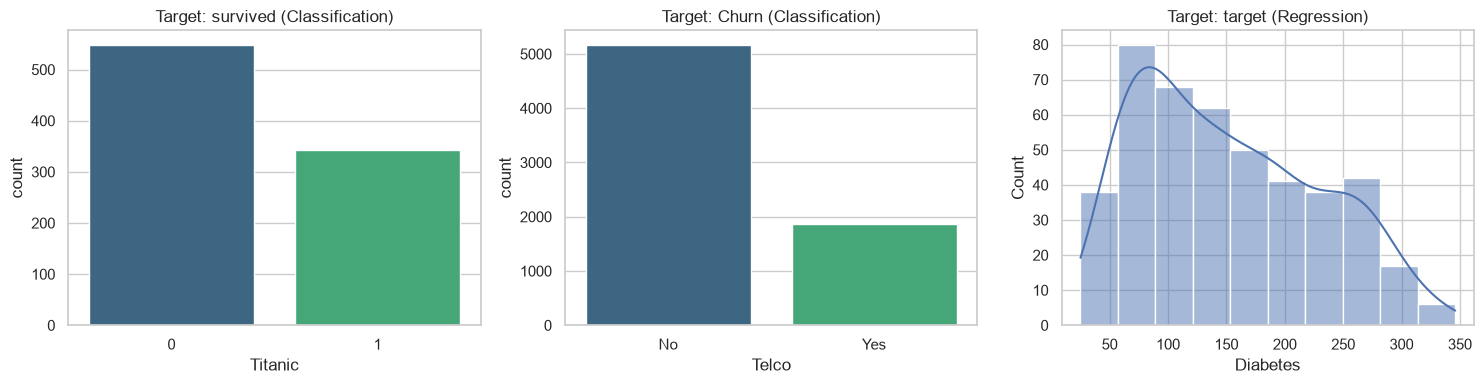

In [54]:
def plot_target(df, target_col, task, ax=None):
    """Draw the target distribution."""
    if ax is None:
        ax = plt.gca()
    if task == "Classification":
        sns.countplot(data=df, x=target_col, hue=target_col, palette="viridis", legend=False, ax=ax)
    else:
        sns.histplot(df[target_col], kde=True, ax=ax)
    ax.set_title(f"Target: {target_col} ({task})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (data, target)) in zip(axes, datasets.items()):
    plot_target(data, target, detect_task(data, target), ax=ax)
    ax.set_xlabel(name.capitalize())
plt.tight_layout()
plt.show()

In [55]:
def detect_basic_leakage(df, target_col):
    """Find ID-like columns and features very highly correlated with the target."""
    data = df.copy()

    # 1. ID-like columns: integer or text, and every row is unique
    id_cols = []
    for col in data.columns:
        if col == target_col:
            continue
        s = data[col]
        is_int_or_text = is_integer_dtype(s) or (not is_numeric_dtype(s))
        if is_int_or_text and s.nunique() == len(data):
            id_cols.append(col)

    # 2. Correlation: turn a text target (Yes/No) into numbers 0/1, only for this check
    if not is_numeric_dtype(data[target_col]):
        data[target_col] = pd.factorize(data[target_col])[0]

    num_cols = data.select_dtypes(include="number").columns
    high_corr = []
    if target_col in num_cols:
        corr = data[num_cols].corr()[target_col].drop(target_col)
        high_corr = [c for c, v in corr.items() if abs(v) > 0.9]   # 0.9 = suspicious level

    return {"id_columns": id_cols, "highly_correlated": high_corr}


The same functions run on every dataset. This shows that MLGuard is **dynamic**.

In [56]:
for name, (data, target) in datasets.items():
    task = detect_task(data, target)
    print("=" * 60)
    print(name.upper(), "| task:", task)
    print("QUALITY   :", audit_quality(data))
    print("OUTLIERS  :", check_outliers(data, target))
    print("IMBALANCE :", check_imbalance(data, target, task))
    print("LEAKAGE   :", detect_basic_leakage(data, target))

TITANIC | task: Classification
QUALITY   : {'missing': {'age': 177, 'embarked': 2, 'deck': 688, 'embark_town': 2}, 'missing_percent': {'age': 19.87, 'embarked': 0.22, 'deck': 77.22, 'embark_town': 0.22}, 'duplicates': 107, 'constant_cols': [], 'wrong_dtypes': []}
OUTLIERS  : {'age': {'count': 11, 'percent': 1.54}, 'sibsp': {'count': 46, 'percent': 5.16}, 'fare': {'count': 116, 'percent': 13.02}}
IMBALANCE : {'applicable': True, 'class_percent': {0: 61.62, 1: 38.38}, 'minority_percent': 38.38, 'severity': 'Low'}
LEAKAGE   : {'id_columns': [], 'highly_correlated': []}
TELCO | task: Classification
QUALITY   : {'missing': {}, 'missing_percent': {}, 'duplicates': 0, 'constant_cols': [], 'wrong_dtypes': ['TotalCharges']}
OUTLIERS  : {}
IMBALANCE : {'applicable': True, 'class_percent': {'No': 73.46, 'Yes': 26.54}, 'minority_percent': 26.54, 'severity': 'Medium'}
LEAKAGE   : {'id_columns': ['customerID'], 'highly_correlated': []}
DIABETES | task: Regression
QUALITY   : {'missing': {}, 'missing

In [57]:
# New imports for Day 2 (you can also paste these into your first import cell)
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (balanced_accuracy_score, accuracy_score, precision_score,
                             recall_score, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score)

In [58]:
def convert_numeric_text(df):
    """Text columns that really hold numbers (like Telco TotalCharges) become numeric.
    Works on a copy. The user's original data is not changed."""
    data = df.copy()
    for col in data.columns:
        if not is_numeric_dtype(data[col]):
            converted = pd.to_numeric(data[col], errors="coerce")
            original_count = data[col].notnull().sum()
            if original_count > 0 and converted.notnull().sum() / original_count > 0.8:
                data[col] = converted
    return data

In [59]:
def prepare_features(df, target_col, exclude_cols=()):
    """Turn a dataframe into numbers only, so scikit-learn can use it."""
    data = convert_numeric_text(df).dropna(subset=[target_col])   # rows without a target are useless
    y = data[target_col]
    if not is_numeric_dtype(y):
        y = pd.Series(pd.factorize(y)[0], index=y.index)   # Yes/No -> 1/0

    X = data.drop(columns=[target_col] + list(exclude_cols))
    categorical = []
    for col in X.columns:
        if is_numeric_dtype(X[col]):
            X[col] = X[col].astype(float)
            X[col] = X[col].fillna(X[col].median())    # fill empty cells with the median
        else:
            X[col] = pd.factorize(X[col])[0]           # text -> number codes (missing = -1)
            categorical.append(col)
    return X, y, categorical

In [60]:
def mutual_info_table(df, target_col, task, exclude_cols=()):
    """Rank features by mutual information with the target."""
    X, y, categorical = prepare_features(df, target_col, exclude_cols)
    is_discrete = [c in categorical for c in X.columns]   # tell sklearn which are categories

    if task == "Classification":
        mi = mutual_info_classif(X, y, discrete_features=is_discrete, random_state=42)
    else:
        mi = mutual_info_regression(X, y, discrete_features=is_discrete, random_state=42)

    table = pd.DataFrame({"feature": X.columns, "mutual_info": mi.round(4)})

    if task == "Classification":
        # ratio_to_max = 1.0 means this feature explains the whole target 
        p = y.value_counts(normalize=True)
        entropy = float(-(p * np.log(p)).sum())
        table["ratio_to_max"] = (table["mutual_info"] / entropy).round(3)

    return table.sort_values("mutual_info", ascending=False).reset_index(drop=True)

In [61]:
def single_feature_test(df, target_col, task, exclude_cols=(), threshold=0.95):
    """Train a small model on ONE column at a time. A near-perfect score = suspicious."""
    X, y, _ = prepare_features(df, target_col, exclude_cols)
    stratify = y if task == "Classification" else None    # keep the class ratio same in both parts
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=stratify)

    rows = []
    for col in X.columns:
        if task == "Classification":
            model = DecisionTreeClassifier(max_depth=5, random_state=42)
            model.fit(X_train[[col]], y_train)
            score = balanced_accuracy_score(y_test, model.predict(X_test[[col]]))
        else:
            model = DecisionTreeRegressor(max_depth=5, random_state=42)
            model.fit(X_train[[col]], y_train)
            score = r2_score(y_test, model.predict(X_test[[col]]))
        rows.append({"feature": col, "score": round(float(score), 3),
                     "suspicious": score >= threshold})

    return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)

In [62]:
def detect_leakage(df, target_col, task):
    """Run all leakage checks and give a reason for every suspicious column."""
    df = convert_numeric_text(df)                      # fix numbers stored as text first
    basic = detect_basic_leakage(df, target_col)       # Day 1 function
    id_cols = basic["id_columns"]

    # Text columns with too many different values (more than half of the rows) make
    # mutual information give fake high numbers, so i skip them in the model checks
    many_values = [c for c in df.columns
                   if c != target_col and not is_numeric_dtype(df[c])
                   and df[c].nunique() > 0.5 * len(df) and c not in id_cols]
    skip = id_cols + many_values

    mi = mutual_info_table(df, target_col, task, exclude_cols=skip)
    single = single_feature_test(df, target_col, task, exclude_cols=skip)

    reasons = {}
    def add(col, why):
        reasons.setdefault(col, []).append(why)

    for c in id_cols:
        add(c, "ID-like column (every row is unique)")
    for c in basic["highly_correlated"]:
        add(c, "correlation with target above 0.9")
    for c in single[single["suspicious"]]["feature"]:
        add(c, "alone predicts the target almost perfectly")
    if task == "Classification":
        for c in mi[mi["ratio_to_max"] >= 0.9]["feature"]:
            add(c, "carries 90%+ of the target information")

    return {"suspicious_columns": reasons, "mutual_info": mi, "single_feature": single}

In [63]:
# Test on all 3 datasets
for name, (data, target) in datasets.items():
    task = detect_task(data, target)
    result = detect_leakage(data, target, task)
    print("=" * 60)
    print(name.upper(), "| suspicious columns:", result["suspicious_columns"])
    print("\nTop 5 by mutual information:")
    print(result["mutual_info"].head(5))
    print("\nTop 5 by single-feature score:")
    print(result["single_feature"].head(5))

TITANIC | suspicious columns: {'alive': ['alone predicts the target almost perfectly', 'carries 90%+ of the target information']}

Top 5 by mutual information:
      feature  mutual_info  ratio_to_max
0       alive       0.6659         1.000
1         who       0.1652         0.248
2         sex       0.1509         0.227
3  adult_male       0.1389         0.209
4        fare       0.1225         0.184

Top 5 by single-feature score:
      feature  score  suspicious
0       alive  1.000        True
1  adult_male  0.765       False
2         who  0.765       False
3         sex  0.758       False
4       class  0.622       False
TELCO | suspicious columns: {'customerID': ['ID-like column (every row is unique)']}

Top 5 by mutual information:
           feature  mutual_info  ratio_to_max
0         Contract       0.0985         0.170
1           tenure       0.0725         0.125
2   OnlineSecurity       0.0647         0.112
3      TechSupport       0.0630         0.109
4  InternetService 

In [64]:
# Proof test: add a FAKE leaky column to Diabetes and check that MLGuard catches it
test_df = datasets["diabetes"][0].copy()
rng = np.random.default_rng(0)
test_df["target_copy"] = test_df["target"] + rng.normal(0, 2, len(test_df))

print(detect_leakage(test_df, "target", "Regression")["suspicious_columns"])

{'target_copy': ['correlation with target above 0.9', 'alone predicts the target almost perfectly']}


In [65]:
def fitness_score(df, quality, outliers, imbalance, suspicious):
    """Give a 0-100 score for the dataset and list the reasons for lost points."""
    n_rows = len(df)
    reasons = []                                       
    # 1. Missing values
    lost = 0
    for col, pct in quality["missing_percent"].items():
        if pct > 50:
            lost += 8
        elif pct > 20:
            lost += 5
        elif pct > 5:
            lost += 3
        else:
            lost += 1
    lost = min(lost, 25)                               
    if lost:
        reasons.append((lost, "Missing values in %d column(s)" % len(quality["missing_percent"])))

    # 2. Duplicates
    dup_pct = quality["duplicates"] / n_rows * 100
    lost = 10 if dup_pct > 10 else (5 if dup_pct > 1 else (2 if dup_pct > 0 else 0))
    if lost:
        reasons.append((lost, "%d duplicate rows (%.1f%%)" % (quality["duplicates"], dup_pct)))

    # 3. Constant columns
    lost = min(3 * len(quality["constant_cols"]), 9)
    if lost:
        reasons.append((lost, "Constant column(s): " + ", ".join(quality["constant_cols"])))

    # 4. Wrong data types
    lost = min(5 * len(quality["wrong_dtypes"]), 10)
    if lost:
        reasons.append((lost, "Wrong data type: " + ", ".join(quality["wrong_dtypes"])))

    # 5. Outliers
    heavy = [c for c, v in outliers.items() if v["percent"] > 5]
    lost = min(2 * len(heavy), 10)
    if lost:
        reasons.append((lost, "Many outliers (>5%) in: " + ", ".join(heavy)))

    # 6. Class imbalance
    if imbalance.get("applicable"):
        lost = {"High": 15, "Medium": 7, "Low": 0}[imbalance["severity"]]
        if lost:
            reasons.append((lost, "Class imbalance is %s (smallest class %.1f%%)"
                            % (imbalance["severity"], imbalance["minority_percent"])))

    #  Leakage: ID columns are a small problem, other suspicious columns are big
    id_only = [c for c, r in suspicious.items() if all(x.startswith("ID-like") for x in r)]
    real_leaks = [c for c in suspicious if c not in id_only]
    lost = min(3 * len(id_only), 9)
    if lost:
        reasons.append((lost, "ID-like column(s): " + ", ".join(id_only)))
    lost = min(20 * len(real_leaks), 40)
    if lost:
        reasons.append((lost, "Possible data leakage in: " + ", ".join(real_leaks)))

    reasons.sort(reverse=True)                         # biggest problem first
    score = max(0, 100 - sum(points for points, _ in reasons))
    grade = "Good" if score >= 85 else ("Needs work" if score >= 60 else "Poor")
    return {"score": score, "grade": grade,
            "reasons": ["-%d points: %s" % (p, t) for p, t in reasons]}

In [66]:
# Run on all 3 datasets
for name, (data, target) in datasets.items():
    task = detect_task(data, target)
    quality = audit_quality(data)
    outliers = check_outliers(data, target)
    imbalance = check_imbalance(data, target, task)
    suspicious = detect_leakage(data, target, task)["suspicious_columns"]

    result = fitness_score(data, quality, outliers, imbalance, suspicious)
    print("=" * 60)
    print(name.upper(), "| Fitness score:", result["score"], "/ 100 |", result["grade"])
    for line in result["reasons"]:
        print("  ", line)

TITANIC | Fitness score: 53 / 100 | Poor
   -20 points: Possible data leakage in: alive
   -13 points: Missing values in 4 column(s)
   -10 points: 107 duplicate rows (12.0%)
   -4 points: Many outliers (>5%) in: sibsp, fare
TELCO | Fitness score: 85 / 100 | Good
   -7 points: Class imbalance is Medium (smallest class 26.5%)
   -5 points: Wrong data type: TotalCharges
   -3 points: ID-like column(s): customerID
DIABETES | Fitness score: 100 / 100 | Good


In [67]:
def prepare_model_data(df, target_col, exclude_cols=()):
    """Make a clean numeric table for models. Text columns become 0/1 columns (one-hot)."""
    data = convert_numeric_text(df).dropna(subset=[target_col])
    y = data[target_col]
    if not is_numeric_dtype(y):
        y = pd.Series(pd.factorize(y)[0], index=y.index)

    X = data.drop(columns=[target_col] + list(exclude_cols))
    numeric_cols = X.select_dtypes(include="number").columns
    for col in list(X.columns):
        if col not in numeric_cols:
            if X[col].nunique() > 50:                  
                X = X.drop(columns=[col])
            else:
                X[col] = X[col].astype(str)            
    X = pd.get_dummies(X, dtype=float)                 
    return X.astype(float), y

In [68]:
def get_models(task):
    """Return the 3 baseline models for the task. Empty cells are filled inside the pipeline."""
    if task == "Classification":
        return {
            "Dummy (always majority)": Pipeline([("fill", SimpleImputer(strategy="median")),
                                                 ("model", DummyClassifier(strategy="most_frequent"))]),
            "Logistic Regression": Pipeline([("fill", SimpleImputer(strategy="median")),
                                             ("scale", StandardScaler()),
                                             ("model", LogisticRegression(max_iter=1000))]),
            "Random Forest": Pipeline([("fill", SimpleImputer(strategy="median")),
                                       ("model", RandomForestClassifier(n_estimators=100, random_state=42))]),
        }
    return {
        "Dummy (always mean)": Pipeline([("fill", SimpleImputer(strategy="median")),
                                         ("model", DummyRegressor(strategy="mean"))]),
        "Linear Regression": Pipeline([("fill", SimpleImputer(strategy="median")),
                                       ("scale", StandardScaler()),
                                       ("model", LinearRegression())]),
        "Random Forest": Pipeline([("fill", SimpleImputer(strategy="median")),
                                   ("model", RandomForestRegressor(n_estimators=100, random_state=42))]),
    }

In [69]:
def run_baseline(df, target_col, task, exclude_cols=()):
    """Split the data, train the 3 models, and return a table of scores."""
    X, y = prepare_model_data(df, target_col, exclude_cols)
    stratify = y if task == "Classification" else None
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=stratify)   # 70% train, 30% test

    rows = []
    for name, model in get_models(task).items():
        model.fit(X_train, y_train)                    # learn from the train part
        pred = model.predict(X_test)                   
        if task == "Classification":
            counts = y.value_counts()
            if len(counts) == 2:
                # two classes: measure the smaller class (for example "customer leaves")
                kw = {"average": "binary", "pos_label": counts.idxmin(), "zero_division": 0}
            else:
                kw = {"average": "macro", "zero_division": 0}
            rows.append({"model": name,
                         "accuracy": round(accuracy_score(y_test, pred), 3),
                         "precision": round(precision_score(y_test, pred, **kw), 3),
                         "recall": round(recall_score(y_test, pred, **kw), 3),
                         "f1": round(f1_score(y_test, pred, **kw), 3)})
        else:
            rows.append({"model": name,
                         "MAE": round(mean_absolute_error(y_test, pred), 2),
                         "RMSE": round(float(np.sqrt(mean_squared_error(y_test, pred))), 2),
                         "R2": round(r2_score(y_test, pred), 3)})

    return pd.DataFrame(rows)

In [70]:
# Run on all 3 datasets (ID columns are removed first, they only add noise)
for name, (data, target) in datasets.items():
    task = detect_task(data, target)
    id_cols = detect_basic_leakage(data, target)["id_columns"]
    print("=" * 60)
    print(name.upper(), "|", task)
    print(run_baseline(data, target, task, exclude_cols=id_cols).to_string(index=False))

TITANIC | Classification
                  model  accuracy  precision  recall  f1
Dummy (always majority)     0.616        0.0     0.0 0.0
    Logistic Regression     1.000        1.0     1.0 1.0
          Random Forest     1.000        1.0     1.0 1.0
TELCO | Classification
                  model  accuracy  precision  recall    f1
Dummy (always majority)     0.735      0.000   0.000 0.000
    Logistic Regression     0.809      0.665   0.563 0.610
          Random Forest     0.784      0.618   0.490 0.547
DIABETES | Regression
              model   MAE  RMSE     R2
Dummy (always mean) 64.26 73.71 -0.006
  Linear Regression 41.92 53.12  0.477
      Random Forest 42.75 53.48  0.470


In [71]:
# PREVIEW of the main idea: Titanic score WITH the leaky column vs WITHOUT it
titanic, t_target = datasets["titanic"]
print("WITH 'alive' (leaky):")
print(run_baseline(titanic, t_target, "Classification").to_string(index=False))
print("\nWITHOUT 'alive':")
print(run_baseline(titanic, t_target, "Classification", exclude_cols=["alive"]).to_string(index=False))

WITH 'alive' (leaky):
                  model  accuracy  precision  recall  f1
Dummy (always majority)     0.616        0.0     0.0 0.0
    Logistic Regression     1.000        1.0     1.0 1.0
          Random Forest     1.000        1.0     1.0 1.0

WITHOUT 'alive':
                  model  accuracy  precision  recall    f1
Dummy (always majority)     0.616      0.000   0.000 0.000
    Logistic Regression     0.817      0.760   0.767 0.763
          Random Forest     0.810      0.789   0.689 0.736


In [72]:
#  Day 3
from scipy.stats import ks_2samp
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
from sklearn.metrics import make_scorer

In [73]:
def compare_before_after(df, target_col, task, suspicious):
    """Run baseline models with and without the leaky columns."""
    # ID-only columns are noise, we remove them in both runs
    id_only = [c for c, r in suspicious.items() if all(x.startswith("ID-like") for x in r)]
    leaky = [c for c in suspicious if c not in id_only]

    before = run_baseline(df, target_col, task, exclude_cols=id_only)
    after = run_baseline(df, target_col, task, exclude_cols=id_only + leaky)
    return {"id_columns": id_only, "leaky_columns": leaky, "before": before, "after": after}

In [74]:
def make_comparison_table(before, after, task):
    """Put before and after scores side by side (F1 for classification, R2 for regression)."""
    metric = "f1" if task == "Classification" else "R2"
    table = before[["model", metric]].merge(after[["model", metric]], on="model",
                                           suffixes=("_before", "_after"))
    table["change"] = (table[metric + "_after"] - table[metric + "_before"]).round(3)
    return table

def plot_before_after(table, task, title, ax=None):
    """Grouped bar chart: before vs after."""
    if ax is None:
        ax = plt.gca()
    metric = "f1" if task == "Classification" else "R2"
    x = np.arange(len(table))
    width = 0.35
    ax.bar(x - width / 2, table[metric + "_before"], width, label="Before (with leaky columns)")
    ax.bar(x + width / 2, table[metric + "_after"], width, label="After (leaky removed)")
    ax.set_xticks(x)
    ax.set_xticklabels([m.split(" (")[0] for m in table["model"]], rotation=15)
    ax.set_ylabel(metric.upper())
    ax.set_title(title)
    ax.legend(fontsize=8)

TITANIC | leaky columns removed in 'After': ['alive']
                  model  f1_before  f1_after  change
Dummy (always majority)        0.0     0.000   0.000
    Logistic Regression        1.0     0.763  -0.237
          Random Forest        1.0     0.736  -0.264
TELCO | leaky columns removed in 'After': []
                  model  f1_before  f1_after  change
Dummy (always majority)      0.000     0.000     0.0
    Logistic Regression      0.610     0.610     0.0
          Random Forest      0.547     0.547     0.0
DIABETES | leaky columns removed in 'After': []
              model  R2_before  R2_after  change
Dummy (always mean)     -0.006    -0.006     0.0
  Linear Regression      0.477     0.477     0.0
      Random Forest      0.470     0.470     0.0


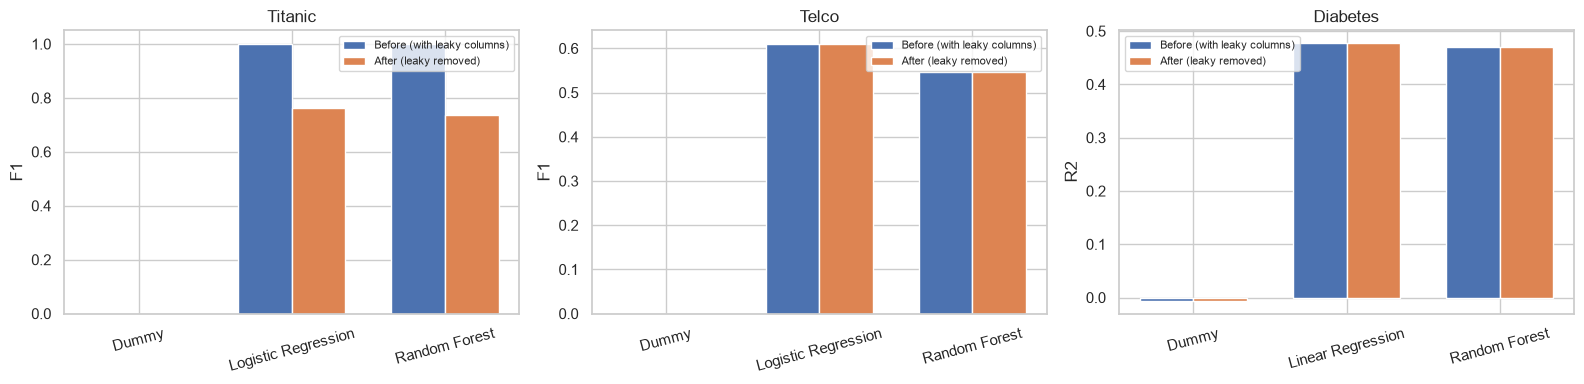

In [75]:
# Run before/after on all 3 datasets
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
before_after_results = {}

for ax, (name, (data, target)) in zip(axes, datasets.items()):
    task = detect_task(data, target)
    suspicious = detect_leakage(data, target, task)["suspicious_columns"]
    result = compare_before_after(data, target, task, suspicious)
    table = make_comparison_table(result["before"], result["after"], task)
    before_after_results[name] = result

    print("=" * 60)
    print(name.upper(), "| leaky columns removed in 'After':", result["leaky_columns"])
    print(table.to_string(index=False))
    plot_before_after(table, task, name.capitalize(), ax=ax)

plt.tight_layout()
plt.show()

In [76]:
def cross_validate_models(df, target_col, task, exclude_cols=(), folds=5):
    """5-fold cross-validation for the 3 baseline models."""
    X, y = prepare_model_data(df, target_col, exclude_cols)

    if task == "Classification":
        counts = y.value_counts()
        if len(counts) == 2:
            # F1 of the smaller class, same idea as run_baseline
            scorer = make_scorer(f1_score, pos_label=counts.idxmin(), zero_division=0)
            metric_name = "F1"
        else:
            scorer, metric_name = "f1_macro", "F1 (macro)"
        cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)
    else:
        scorer, metric_name = "r2", "R2"
        cv = KFold(n_splits=folds, shuffle=True, random_state=42)

    rows = []
    for model_name, model in get_models(task).items():
        scores = cross_val_score(model, X, y, cv=cv, scoring=scorer)
        rows.append({"model": model_name, "metric": metric_name,
                     "mean": round(scores.mean(), 3), "std": round(scores.std(), 3)})
    return pd.DataFrame(rows)

In [77]:
# Cross-validation on the 'After' data (leaky columns removed).
for name, (data, target) in datasets.items():
    task = detect_task(data, target)
    r = before_after_results[name]
    skip = r["id_columns"] + r["leaky_columns"]
    print("=" * 60)
    print(name.upper(), "| 5-fold cross-validation")
    print(cross_validate_models(data, target, task, exclude_cols=skip).to_string(index=False))
    

TITANIC | 5-fold cross-validation
                  model metric  mean   std
Dummy (always majority)     F1 0.000 0.000
    Logistic Regression     F1 0.760 0.033
          Random Forest     F1 0.739 0.027
TELCO | 5-fold cross-validation
                  model metric  mean   std
Dummy (always majority)     F1 0.000 0.000
    Logistic Regression     F1 0.599 0.030
          Random Forest     F1 0.549 0.028
DIABETES | 5-fold cross-validation
              model metric   mean   std
Dummy (always mean)     R2 -0.019 0.014
  Linear Regression     R2  0.478 0.085
      Random Forest     R2  0.429 0.084


In [78]:
def find_failure_groups(df, target_col, task, exclude_cols=(), min_size=20, top_n=8):
    """Find groups of rows where the Random Forest makes the most errors."""
    df = df.reset_index(drop=True)
    X, y = prepare_model_data(df, target_col, exclude_cols)
    stratify = y if task == "Classification" else None
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=stratify)

    model = get_models(task)["Random Forest"]
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    # Error for every test row
    if task == "Classification":
        error = pd.Series((pred != y_test.values).astype(float), index=y_test.index)
        error_type = "error rate"
    else:
        error = pd.Series(np.abs(pred - y_test.values), index=y_test.index)
        error_type = "mean absolute error"
    overall = float(error.mean())

    # Original (readable) columns of the test rows, so groups have real names
    test_rows = convert_numeric_text(df).loc[y_test.index]

    rows = []
    for col in test_rows.columns:
        if col == target_col or col in exclude_cols:
            continue
        s = test_rows[col]

        if is_numeric_dtype(s) and s.nunique() > 10:
            groups = pd.qcut(s, 4, duplicates="drop").astype(str)   # 4 value ranges
        elif s.nunique() <= 20:
            groups = s.astype(str)                                  # each category is a group
        else:
            continue                                                # too many values, skip
        groups = groups.replace("nan", "missing")

        summary = pd.DataFrame({"group": groups.values, "error": error.values}) \
                    .groupby("group")["error"].agg(["count", "mean"])
        for group_name, r in summary.iterrows():
            if r["count"] >= min_size:                              # skip tiny groups
                rows.append({"feature": col, "group": group_name, "rows": int(r["count"]),
                             "error": round(float(r["mean"]), 3),
                             "times_overall": round(float(r["mean"]) / overall, 2) if overall > 0 else np.nan})

    table = pd.DataFrame(rows).sort_values("error", ascending=False).head(top_n)
    return {"error_type": error_type, "overall_error": round(overall, 3),
            "worst_groups": table.reset_index(drop=True)}

In [79]:
def plot_failure_groups(result, title, ax=None):
    """Horizontal bars of the worst groups, with a line for the overall error."""
    if ax is None:
        ax = plt.gca()
    t = result["worst_groups"].iloc[::-1]               # reverse, so the worst is on top
    labels = [f"{f} = {g}" for f, g in zip(t["feature"], t["group"])]
    ax.barh(labels, t["error"], color="tomato")
    ax.axvline(result["overall_error"], color="black", linestyle="--", label="overall")
    ax.set_title(title)
    ax.set_xlabel(result["error_type"])
    ax.legend(fontsize=8)

TITANIC | overall error rate = 0.19
    feature         group  rows  error  times_overall
       deck             C    24  0.375           1.97
   embarked             C    44  0.318           1.67
embark_town     Cherbourg    44  0.318           1.67
      sibsp             1    68  0.265           1.39
      class         First    69  0.261           1.37
     pclass             1    69  0.261           1.37
        age (19.25, 27.0]    56  0.250           1.31
        who         child    29  0.241           1.27
TELCO | overall error rate = 0.216
         feature            group  rows  error  times_overall
        Contract   Month-to-month  1171  0.332           1.54
   PaymentMethod Electronic check   711  0.326           1.51
          tenure    (-0.001, 8.0]   532  0.323           1.50
  OnlineSecurity               No  1059  0.313           1.45
 InternetService      Fiber optic   919  0.311           1.44
   SeniorCitizen                1   348  0.305           1.41
DevicePro

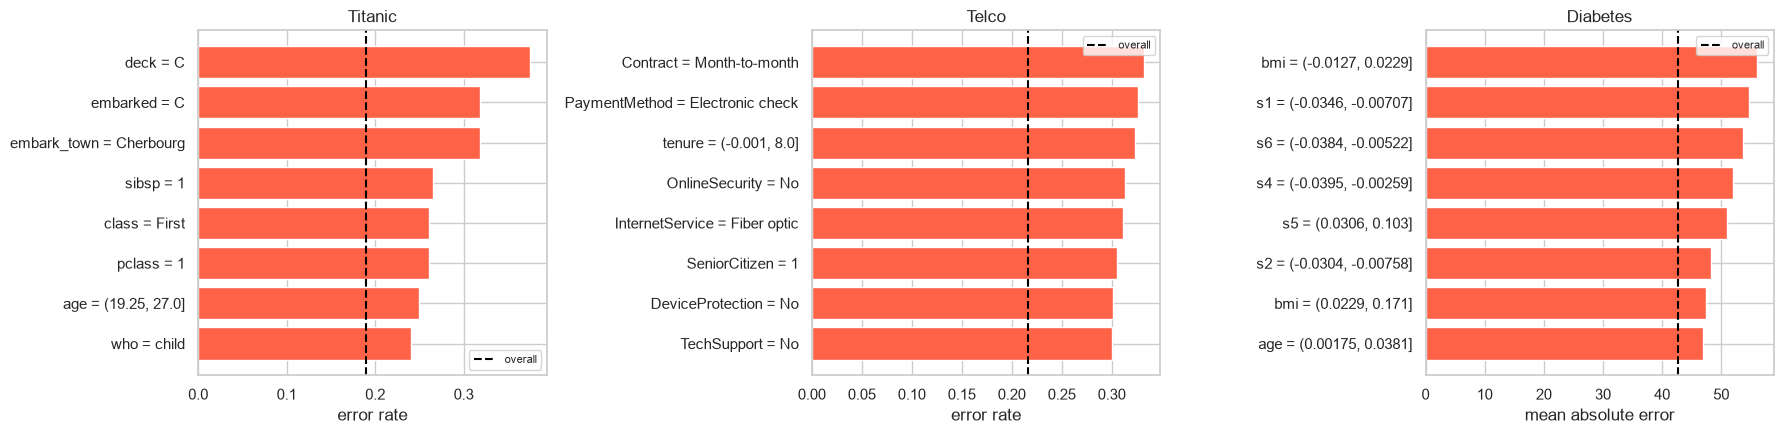

In [80]:
# Failure groups on all 3 datasets (suspicious columns removed first)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
failure_results = {}

for ax, (name, (data, target)) in zip(axes, datasets.items()):
    task = detect_task(data, target)
    r = before_after_results[name]
    skip = r["id_columns"] + r["leaky_columns"]
    result = find_failure_groups(data, target, task, exclude_cols=skip)
    failure_results[name] = result

    print("=" * 60)
    print(name.upper(), "| overall", result["error_type"], "=", result["overall_error"])
    print(result["worst_groups"].to_string(index=False))
    plot_failure_groups(result, name.capitalize(), ax=ax)

plt.tight_layout()
plt.show()

In [81]:
def calculate_psi(train_values, test_values, bins=10):
    """PSI for a numeric column. Bins come from the train data."""
    e_vals = pd.Series(train_values).dropna()
    a_vals = pd.Series(test_values).dropna()
    bins = min(bins, max(3, len(a_vals) // 30))         # small data = fewer bins (about 30 rows per bin)
    edges = np.unique(np.quantile(e_vals, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf               # catch values outside the train range
    e = np.histogram(e_vals, bins=edges)[0] / len(e_vals)
    a = np.histogram(a_vals, bins=edges)[0] / len(a_vals)
    e, a = np.clip(e, 0.0001, None), np.clip(a, 0.0001, None)   # avoid log(0)
    return float(np.sum((a - e) * np.log(a / e)))

def calculate_psi_categorical(train_values, test_values):
    """PSI for a category column, using the share of each category."""
    e = pd.Series(train_values).astype(str).value_counts(normalize=True)
    a = pd.Series(test_values).astype(str).value_counts(normalize=True)
    cats = e.index.union(a.index)
    e = e.reindex(cats, fill_value=0).clip(lower=0.0001)
    a = a.reindex(cats, fill_value=0).clip(lower=0.0001)
    return float(np.sum((a - e) * np.log(a / e)))

def psi_severity(psi):
    return "Low" if psi < 0.1 else ("Medium" if psi < 0.25 else "High")

In [82]:
def drift_report(train_df, test_df, target_col):
    """Compare train and test for every feature. Returns one row per feature."""
    train_df, test_df = convert_numeric_text(train_df), convert_numeric_text(test_df)
    rows = []
    for col in train_df.columns:
        if col == target_col:
            continue
        tr, te = train_df[col], test_df[col]

        if is_numeric_dtype(tr) and tr.nunique() > 10:
            # numeric: KS test + PSI
            ks = ks_2samp(tr.dropna(), te.dropna())
            psi = calculate_psi(tr, te)
            rows.append({"feature": col, "type": "numeric",
                         "ks_statistic": round(float(ks.statistic), 3),
                         "p_value": round(float(ks.pvalue), 4),
                         "psi": round(psi, 3), "severity": psi_severity(psi)})
        elif tr.nunique() <= 20:
            # category: biggest percentage difference + PSI
            e = tr.astype(str).value_counts(normalize=True)
            a = te.astype(str).value_counts(normalize=True)
            cats = e.index.union(a.index)
            gap = (a.reindex(cats, fill_value=0) - e.reindex(cats, fill_value=0)).abs().max() * 100
            psi = calculate_psi_categorical(tr, te)
            rows.append({"feature": col, "type": "category",
                         "ks_statistic": np.nan, "p_value": np.nan,
                         "max_category_gap_%": round(float(gap), 1),
                         "psi": round(psi, 3), "severity": psi_severity(psi)})
    return pd.DataFrame(rows).sort_values("psi", ascending=False).reset_index(drop=True)

In [83]:
# Test 1: normal random split. We expect Low drift everywhere.
for name, (data, target) in datasets.items():
    train, test = train_test_split(data, test_size=0.3, random_state=42)
    report = drift_report(train, test, target)
    print("=" * 60)
    print(name.upper(), "| random split | max PSI =", report["psi"].max())
    print(report.head(3).to_string(index=False))

TITANIC | random split | max PSI = 0.113
feature     type  ks_statistic  p_value  max_category_gap_%   psi severity
   deck category           NaN      NaN                10.0 0.113   Medium
  sibsp category           NaN      NaN                 3.8 0.095      Low
   fare  numeric         0.051   0.6922                 NaN 0.033      Low
TELCO | random split | max PSI = 0.008
       feature     type  ks_statistic  p_value  max_category_gap_%   psi severity
MonthlyCharges  numeric         0.018   0.7061                 NaN 0.008      Low
  TotalCharges  numeric         0.017   0.7693                 NaN 0.007      Low
        gender category           NaN      NaN                 3.8 0.006      Low
DIABETES | random split | max PSI = 0.115
feature    type  ks_statistic  p_value   psi severity  max_category_gap_%
     s4 numeric         0.077   0.6036 0.115   Medium                 NaN
    bmi numeric         0.120   0.1223 0.068      Low                 NaN
     bp numeric         0.08

In [84]:
# Test 2: a sorted split on purpose (train = low values, test = high values).
# This proves that the drift check can really find drift.
def sorted_split(df, target_col):
    data = convert_numeric_text(df)
    numeric = [c for c in data.select_dtypes(include="number").columns
               if c != target_col and data[c].nunique() > 10]
    column = numeric[0]
    ordered = df.loc[data.sort_values(column).index]
    cut = int(len(ordered) * 0.7)
    return ordered.iloc[:cut], ordered.iloc[cut:], column

for name, (data, target) in datasets.items():
    train, test, column = sorted_split(data, target)
    report = drift_report(train, test, target)
    print("=" * 60)
    print(name.upper(), "| split sorted by:", column)
    print(report.head(4).to_string(index=False))

TITANIC | split sorted by: age
feature     type  ks_statistic  p_value  max_category_gap_%   psi severity
    age  numeric         0.989      0.0                 NaN 6.054     High
    who category           NaN      NaN                13.6 0.987     High
   deck category           NaN      NaN                10.5 0.418     High
  sibsp category           NaN      NaN                 9.7 0.388     High
TELCO | split sorted by: tenure
      feature     type  ks_statistic  p_value  max_category_gap_%   psi severity
       tenure  numeric         0.996      0.0                 NaN 8.338     High
 TotalCharges  numeric         0.642      0.0                 NaN 4.932     High
     Contract category           NaN      NaN                58.5 1.891     High
PaymentMethod category           NaN      NaN                17.6 0.490     High
DIABETES | split sorted by: age
feature    type  ks_statistic  p_value   psi severity  max_category_gap_%
    age numeric         0.997   0.0000 6.712     Hi

Day 3 Completed

In [85]:
def _safe(results, step, func, *args, **kwargs):
    """Run one audit step. If it fails, save the error and continue (the audit never crashes fully)."""
    try:
        return func(*args, **kwargs)
    except Exception as e:
        results["errors"][step] = type(e).__name__ + ": " + str(e)
        return None


def audit(df, target, run_cv=True):
    """Run the complete MLGuard audit and return one results dictionary."""
    if target not in df.columns:
        raise ValueError("Target column '%s' not found. Columns are: %s" % (target, list(df.columns)))
    if len(df) < 50:
        raise ValueError("Need at least 50 rows for a meaningful audit.")

    results = {"target": target, "n_rows": len(df), "n_cols": df.shape[1], "errors": {}}

    # 1. Task, quality, outliers, imbalance (Day 1)
    task = detect_task(df, target)
    results["task"] = task
    empty_quality = {"missing": {}, "missing_percent": {}, "duplicates": 0,
                     "constant_cols": [], "wrong_dtypes": []}
    results["quality"] = _safe(results, "quality", audit_quality, df) or empty_quality
    results["outliers"] = _safe(results, "outliers", check_outliers, df, target) or {}
    results["imbalance"] = _safe(results, "imbalance", check_imbalance, df, target, task) or {"applicable": False}

    # 2. Leakage (Day 2)
    leak = _safe(results, "leakage", detect_leakage, df, target, task)
    suspicious = leak["suspicious_columns"] if leak else {}
    results["leakage"] = suspicious
    results["mutual_info"] = leak["mutual_info"] if leak else None
    results["single_feature"] = leak["single_feature"] if leak else None

    # 3. Fitness score (Day 2)
    results["fitness"] = _safe(results, "fitness", fitness_score, df, results["quality"],
                               results["outliers"], results["imbalance"], suspicious)

    # 4. Before/after baseline models (Day 2 and 3)
    ba = _safe(results, "before_after", compare_before_after, df, target, task, suspicious)
    results["before_after"] = ba
    results["comparison"] = make_comparison_table(ba["before"], ba["after"], task) if ba else None

    # 5. Cross-validation on the honest data (Day 3)
    skip = (ba["id_columns"] + ba["leaky_columns"]) if ba else []
    results["cv"] = _safe(results, "cross_validation", cross_validate_models, df, target, task, skip) if run_cv else None

    # 6. Failure groups (Day 3)
    results["failure"] = _safe(results, "failure_groups", find_failure_groups, df, target, task, skip)

    # 7. Drift between a random train part and test part (Day 3)
    train_part, test_part = train_test_split(df, test_size=0.3, random_state=42)
    results["drift"] = _safe(results, "drift", drift_report, train_part, test_part, target)

    # 8. Target summary (used by the dashboard chart)
    if task == "Classification":
        results["target_summary"] = results["imbalance"].get("class_percent", {})
    else:
        counts, edges = np.histogram(df[target].dropna(), bins=20)
        results["target_summary"] = {"counts": counts, "edges": edges}

    # 9. Plain English findings
    results["findings"] = make_findings(results)
    return results

In [86]:
def make_findings(results):
    """Turn all numbers into plain English problems with a severity and a fix."""
    findings = []
    def add(severity, issue, fix, priority=5):
        # priority: smaller number = shown first inside the same severity
        findings.append({"severity": severity, "issue": issue, "fix": fix, "priority": priority})

    q = results["quality"]

    # Missing values
    small = []
    for col, pct in q["missing_percent"].items():
        if pct > 50:
            add("High", "Column '%s' is %.1f%% empty." % (col, pct),
                "Drop this column, or collect the missing data.")
        elif pct > 5:
            add("Medium", "Column '%s' is %.1f%% empty." % (col, pct),
                "Fill empty cells (median for numbers, most common value for text) and test if it helps.")
        else:
            small.append(col)
    if small:
        add("Low", "A few empty cells (under 5%%) in: %s." % ", ".join(small),
            "Fill them or drop those rows.")

    # Duplicates
    n_dup, n_rows = q["duplicates"], results["n_rows"]
    if n_dup > 0:
        pct = n_dup / n_rows * 100
        sev = "High" if pct > 10 else ("Medium" if pct > 1 else "Low")
        add(sev, "%d duplicate rows (%.1f%% of the data)." % (n_dup, pct),
            "Check if they are real repeats. If not, remove them with df.drop_duplicates().")

    # Constant columns and wrong data types
    if q["constant_cols"]:
        add("Medium", "Constant column(s): %s. Every row has the same value." % ", ".join(q["constant_cols"]),
            "Remove them, they carry no information.")
    if q["wrong_dtypes"]:
        add("Medium", "Numbers stored as text in: %s." % ", ".join(q["wrong_dtypes"]),
            "Convert with pd.to_numeric(col, errors='coerce'). Blank spaces become empty cells.")

    # Outliers
    heavy = [c for c, v in results["outliers"].items() if v["percent"] > 5]
    light = [c for c, v in results["outliers"].items() if v["percent"] <= 5]
    if heavy:
        add("Medium", "Many outliers (over 5%%) in: %s." % ", ".join(heavy),
            "Check if they are real values. Keep real ones; cap or fix the wrong ones.")
    if light:
        add("Low", "A few outliers in: %s." % ", ".join(light),
            "Usually fine for tree models. Check for data entry mistakes.")

    # Class imbalance
    imb = results["imbalance"]
    if imb.get("applicable") and imb["severity"] in ("High", "Medium"):
        add(imb["severity"], "Class imbalance: the smallest class is only %.1f%% of the data." % imb["minority_percent"],
            "Do not trust accuracy alone. Look at recall and F1, try class_weight='balanced' or resampling.")

    # Leakage
    comp = results["comparison"]
    metric = "f1" if results["task"] == "Classification" else "R2"
    id_only, real = [], []
    for col, reasons in results["leakage"].items():
        if all(r.startswith("ID-like") for r in reasons):
            id_only.append(col)
        else:
            real.append((col, reasons))
    if id_only:
        add("Medium", "ID-like column(s): %s. Every row has a different value." % ", ".join(id_only),
            "Remove before modelling, an ID has no predictive meaning.")
    for col, reasons in real:
        strong = any(not r.startswith("correlation") for r in reasons)
        add("High" if strong else "Medium",
            "Column '%s' looks like leakage (%s)." % (col, "; ".join(reasons)),
            "Remove it if it is not known at prediction time. If it is a real feature, keep it.",
            priority=0)
    if comp is not None and real:
        rf = comp[comp["model"] == "Random Forest"]
        if len(rf):
            before, after = float(rf[metric + "_before"].iloc[0]), float(rf[metric + "_after"].iloc[0])
            if before - after > 0.05:
                strong_any = any(any(not r.startswith("correlation") for r in reasons) for _, reasons in real)
                if strong_any:
                    add("High", "Removing the suspicious columns changed %s from %.2f to %.2f (Random Forest). "
                                "The first score was probably too good to be true." % (metric.upper(), before, after),
                        "Report the 'after' score. Do not use the leaky columns.", priority=1)
                else:
                    # flagged only by correlation: it may be a very good REAL feature, so stay neutral
                    add("Medium", "Removing the correlated column(s) changed %s from %.2f to %.2f (Random Forest). "
                                  "Such a useful column is either a strong real feature or a leak." % (metric.upper(), before, after),
                        "Ask: will this column be known at prediction time? If yes, keep it. If no, remove it.", priority=1)

    # Model strength (simple rules)
    if comp is not None:
        non_dummy = comp[~comp["model"].str.startswith("Dummy")]
        best = float(non_dummy[metric + "_after"].max())
        if results["task"] == "Classification" and best < 0.5:
            add("Medium", "The best model finds the smaller class with F1 of only %.2f." % best,
                "Add better features, collect more data, or check class imbalance.")
        if results["task"] == "Regression" and best < 0.3:
            add("Medium", "The best model explains little of the target (R2 = %.2f)." % best,
                "Add better features or collect more data.")

    # Stability
    cv = results["cv"]
    if cv is not None:
        best_row = cv[~cv["model"].str.startswith("Dummy")].sort_values("mean", ascending=False).iloc[0]
        if best_row["std"] > 0.05:
            add("Low", "The %s score changes between folds (std = %.3f)." % (best_row["metric"], best_row["std"]),
                "Report the cross-validation average, not a single split.")

    # Failure groups
    fail = results["failure"]
    if fail is not None and len(fail["worst_groups"]):
        top = fail["worst_groups"].iloc[0]
        if top["times_overall"] >= 1.3:
            add("Medium", "The model is weakest for %s = %s (%s %.3f, about %.1f times the normal)." %
                (top["feature"], top["group"], fail["error_type"], top["error"], top["times_overall"]),
                "Collect more data for this group, add features for it, or build a separate model.")

    # Drift
    drift = results["drift"]
    if drift is not None:
        high = drift[drift["severity"] == "High"]["feature"].tolist()
        medium = drift[drift["severity"] == "Medium"]["feature"].tolist()
        if high:
            add("High", "Strong drift between train and test in: %s." % ", ".join(high),
                "Check how the data was collected or split. Retrain on newer data.")
        if medium:
            add("Medium", "Some drift between train and test in: %s. On small data this can be random noise." % ", ".join(medium),
                "Check with more data before acting.")

    order = {"High": 0, "Medium": 1, "Low": 2}
    findings.sort(key=lambda x: (order[x["severity"]], x["priority"]))   # High first, leakage first
    return findings

In [87]:
def report_text(results, name="dataset"):
    """Build the full audit report as plain English text."""
    L = []
    line = "=" * 64
    L += [line, "MLGUARD AUDIT REPORT: " + name.upper(), line]
    L.append("Rows: %d | Columns: %d | Target: %s | Task: %s" %
             (results["n_rows"], results["n_cols"], results["target"], results["task"]))

    fit = results["fitness"]
    findings = results["findings"]
    n = {s: sum(1 for f in findings if f["severity"] == s) for s in ("High", "Medium", "Low")}
    L.append("")
    if fit:
        L.append("FITNESS SCORE: %d / 100 (%s)" % (fit["score"], fit["grade"]))
        for r in fit["reasons"]:
            L.append("   " + r)
    L.append("")
    L.append("SUMMARY IN PLAIN ENGLISH")
    L.append("We found %d high, %d medium and %d low severity issues." % (n["High"], n["Medium"], n["Low"]))
    if findings:
        L.append("The most important one: " + findings[0]["issue"])
    else:
        L.append("Our checks found no problems. This does not mean the data is perfect.")

    L += ["", "ISSUES AND HOW TO FIX THEM"]
    for i, f in enumerate(findings, 1):
        L.append("%d. [%s] %s" % (i, f["severity"].upper(), f["issue"]))
        L.append("      Fix: " + f["fix"])

    if results["comparison"] is not None:
        L += ["", "MODEL SCORES: BEFORE vs AFTER removing suspicious columns",
              results["comparison"].to_string(index=False)]
    if results["cv"] is not None:
        L += ["", "CROSS-VALIDATION (5 folds, honest data)", results["cv"].to_string(index=False)]
    fail = results["failure"]
    if fail is not None:
        L += ["", "WHERE THE MODEL FAILS MOST (overall %s = %s)" % (fail["error_type"], fail["overall_error"]),
              fail["worst_groups"].head(5).to_string(index=False)]
    if results["drift"] is not None:
        L += ["", "DRIFT CHECK (train vs test, top 5 by PSI)",
              results["drift"].head(5).to_string(index=False)]
    if results["errors"]:
        L += ["", "STEPS THAT FAILED (the rest of the audit still ran):"]
        for step, msg in results["errors"].items():
            L.append("   %s: %s" % (step, msg))
    L += ["", "Note: all flags are warnings, not proof. A human should check them.", line]
    return "\n".join(L)

In [88]:
def plot_dashboard(results, name="dataset"):
    """One picture with 6 charts that summarise the audit."""
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    fig.suptitle("MLGuard Audit: " + name, fontsize=16, fontweight="bold")

    # 1. Fitness score
    ax = axes[0, 0]
    fit = results["fitness"]
    if fit:
        color = "seagreen" if fit["score"] >= 85 else ("orange" if fit["score"] >= 60 else "tomato")
        ax.barh(["Fitness"], [fit["score"]], color=color)
        ax.set_xlim(0, 100)
        ax.text(fit["score"] / 2, 0, "%d / 100 (%s)" % (fit["score"], fit["grade"]),
                ha="center", va="center", color="white", fontsize=14, fontweight="bold")
    ax.set_title("Dataset fitness score")

    # 2. Target
    ax = axes[0, 1]
    ts = results["target_summary"]
    if results["task"] == "Classification":
        ax.bar([str(k) for k in ts.keys()], list(ts.values()), color="steelblue")
        ax.set_ylabel("percent of rows")
    else:
        ax.bar(ts["edges"][:-1], ts["counts"], width=np.diff(ts["edges"]), align="edge", color="steelblue")
        ax.set_ylabel("rows")
    ax.set_title("Target: " + results["target"])

    # 3. Missing values
    ax = axes[0, 2]
    mp = results["quality"]["missing_percent"]
    if mp:
        top = sorted(mp.items(), key=lambda kv: kv[1], reverse=True)[:10]
        ax.barh([k for k, _ in top][::-1], [v for _, v in top][::-1], color="salmon")
        ax.set_xlabel("% empty")
    else:
        ax.text(0.5, 0.5, "No missing values", ha="center", va="center", fontsize=13)
        ax.axis("off")
    ax.set_title("Missing values")

    # 4. Before / after
    ax = axes[1, 0]
    if results["comparison"] is not None:
        plot_before_after(results["comparison"], results["task"], "Before vs after removing leaks", ax=ax)
    else:
        ax.axis("off")

    # 5. Failure groups
    ax = axes[1, 1]
    if results["failure"] is not None and len(results["failure"]["worst_groups"]):
        plot_failure_groups(results["failure"], "Where the model fails most", ax=ax)
    else:
        ax.axis("off")

    # 6. Drift
    ax = axes[1, 2]
    if results["drift"] is not None and len(results["drift"]):
        d = results["drift"].head(8).iloc[::-1]
        ax.barh(d["feature"], d["psi"], color="mediumpurple")
        ax.axvline(0.1, color="orange", linestyle="--", label="0.1 (medium)")
        ax.axvline(0.25, color="red", linestyle="--", label="0.25 (high)")
        ax.set_xlabel("PSI")
        ax.legend(fontsize=8)
    else:
        ax.axis("off")
    ax.set_title("Drift (train vs test)")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    return fig


def show_report(results, name="dataset", save_dir=None):
    """Print the report and show the dashboard. If save_dir is given, save both files."""
    text = report_text(results, name)
    print(text)
    fig = plot_dashboard(results, name)
    if save_dir:
        import os
        os.makedirs(save_dir, exist_ok=True)
        with open(os.path.join(save_dir, name + "_report.txt"), "w", encoding="utf-8") as f:
            f.write(text)
        fig.savefig(os.path.join(save_dir, name + "_dashboard.png"), dpi=130, bbox_inches="tight")
    plt.show()


def audit_csv(path, target, run_cv=True):
    """Convenience: read any CSV file and audit it."""
    return audit(pd.read_csv(path), target, run_cv=run_cv)

MLGUARD AUDIT REPORT: TITANIC
Rows: 891 | Columns: 15 | Target: survived | Task: Classification

FITNESS SCORE: 53 / 100 (Poor)
   -20 points: Possible data leakage in: alive
   -13 points: Missing values in 4 column(s)
   -10 points: 107 duplicate rows (12.0%)
   -4 points: Many outliers (>5%) in: sibsp, fare

SUMMARY IN PLAIN ENGLISH
We found 4 high, 4 medium and 2 low severity issues.
The most important one: Column 'alive' looks like leakage (alone predicts the target almost perfectly; carries 90%+ of the target information).

ISSUES AND HOW TO FIX THEM
1. [HIGH] Column 'alive' looks like leakage (alone predicts the target almost perfectly; carries 90%+ of the target information).
      Fix: Remove it if it is not known at prediction time. If it is a real feature, keep it.
2. [HIGH] Removing the suspicious columns changed F1 from 1.00 to 0.74 (Random Forest). The first score was probably too good to be true.
      Fix: Report the 'after' score. Do not use the leaky columns.
3. [HIGH

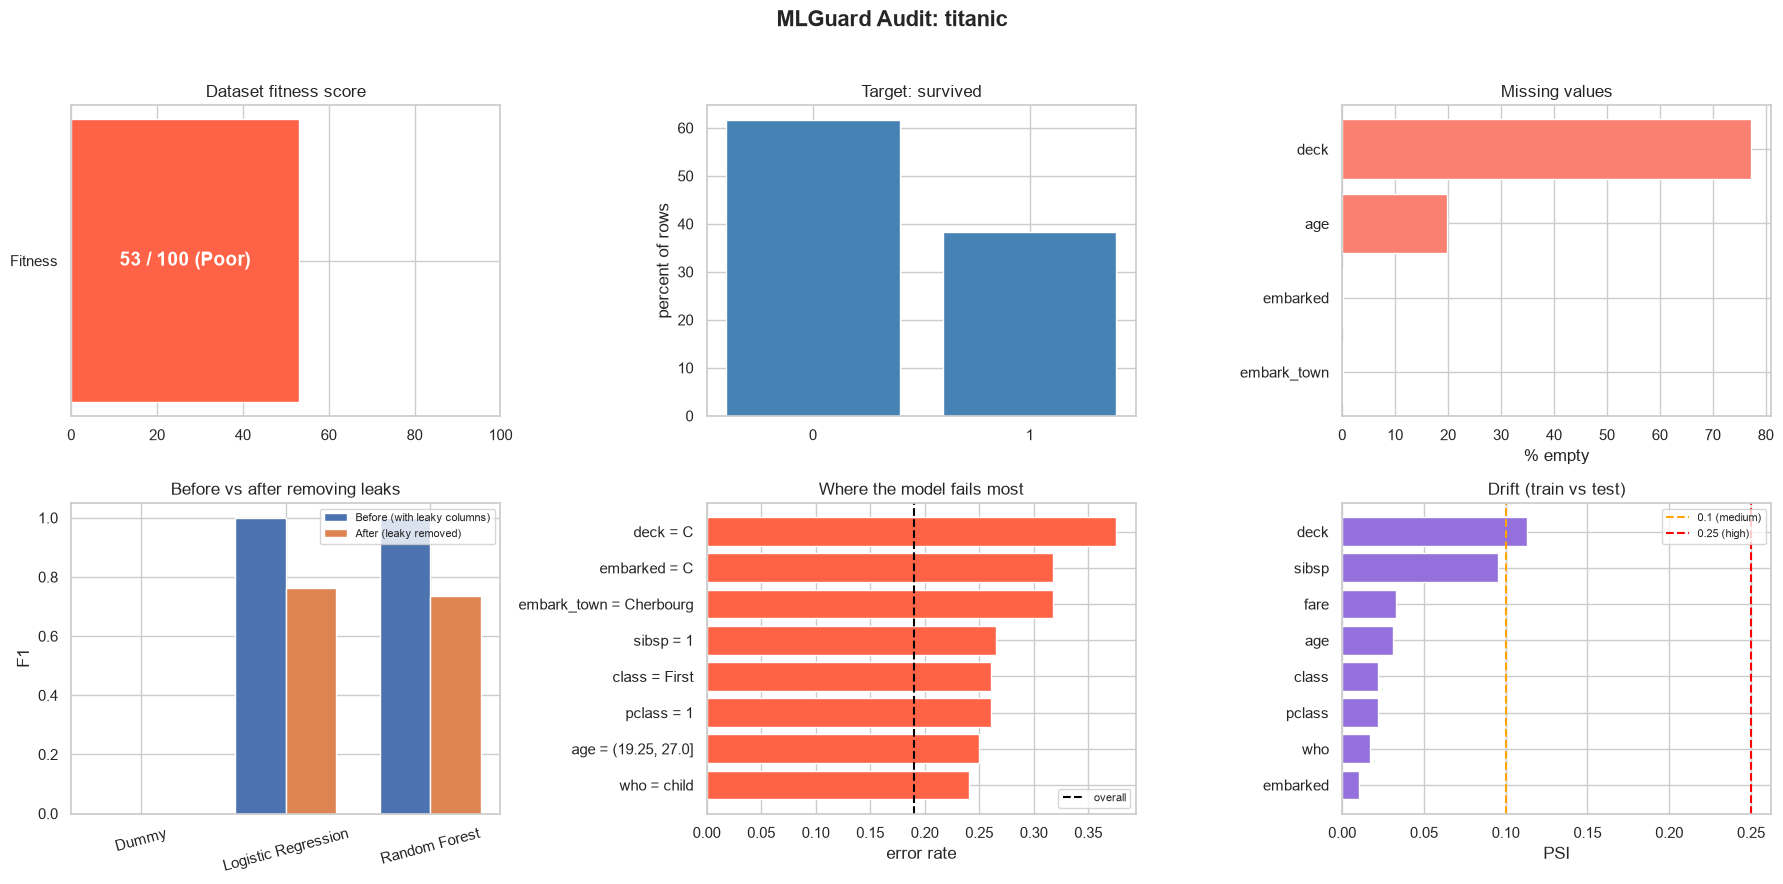

MLGUARD AUDIT REPORT: TELCO
Rows: 7043 | Columns: 21 | Target: Churn | Task: Classification

FITNESS SCORE: 85 / 100 (Good)
   -7 points: Class imbalance is Medium (smallest class 26.5%)
   -5 points: Wrong data type: TotalCharges
   -3 points: ID-like column(s): customerID

SUMMARY IN PLAIN ENGLISH
We found 0 high, 4 medium and 0 low severity issues.
The most important one: Numbers stored as text in: TotalCharges.

ISSUES AND HOW TO FIX THEM
1. [MEDIUM] Numbers stored as text in: TotalCharges.
      Fix: Convert with pd.to_numeric(col, errors='coerce'). Blank spaces become empty cells.
2. [MEDIUM] Class imbalance: the smallest class is only 26.5% of the data.
      Fix: Do not trust accuracy alone. Look at recall and F1, try class_weight='balanced' or resampling.
3. [MEDIUM] ID-like column(s): customerID. Every row has a different value.
      Fix: Remove before modelling, an ID has no predictive meaning.
4. [MEDIUM] The model is weakest for Contract = Month-to-month (error rate 0.332

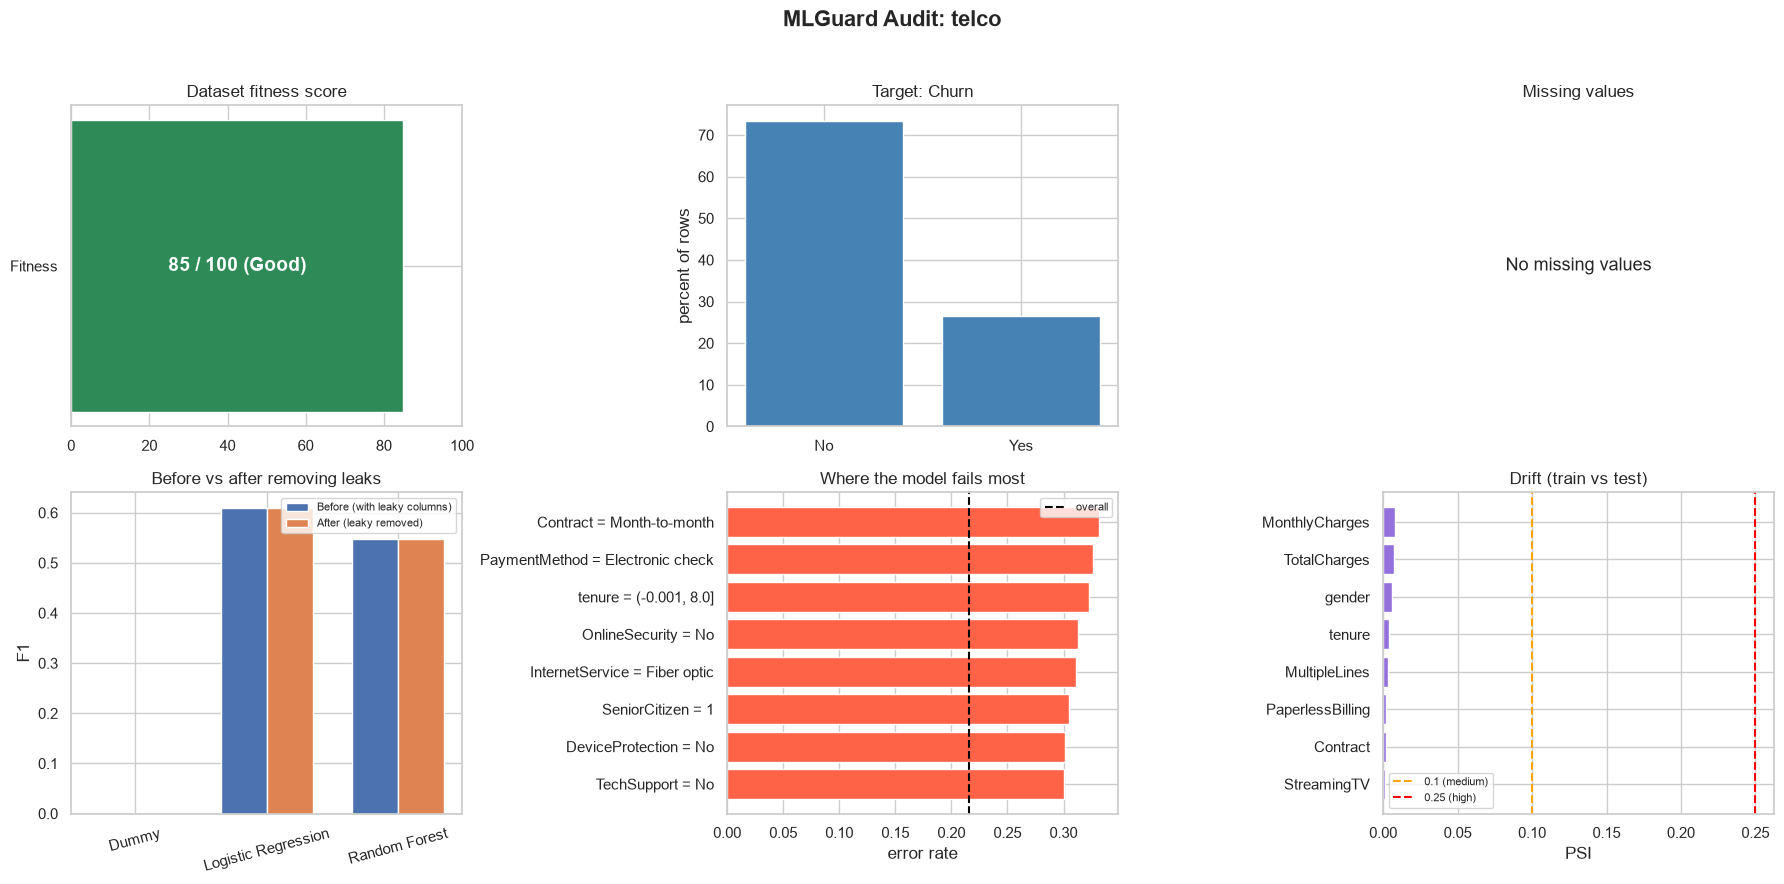

MLGUARD AUDIT REPORT: DIABETES
Rows: 442 | Columns: 11 | Target: target | Task: Regression

FITNESS SCORE: 100 / 100 (Good)

SUMMARY IN PLAIN ENGLISH
We found 0 high, 2 medium and 2 low severity issues.
The most important one: The model is weakest for bmi = (-0.0127, 0.0229] (mean absolute error 56.106, about 1.3 times the normal).

ISSUES AND HOW TO FIX THEM
1. [MEDIUM] The model is weakest for bmi = (-0.0127, 0.0229] (mean absolute error 56.106, about 1.3 times the normal).
      Fix: Collect more data for this group, add features for it, or build a separate model.
2. [MEDIUM] Some drift between train and test in: s4. On small data this can be random noise.
      Fix: Check with more data before acting.
3. [LOW] A few outliers in: bmi, s1, s2, s3, s4, s5, s6.
      Fix: Usually fine for tree models. Check for data entry mistakes.
4. [LOW] The R2 score changes between folds (std = 0.085).
      Fix: Report the cross-validation average, not a single split.

MODEL SCORES: BEFORE vs AFTE

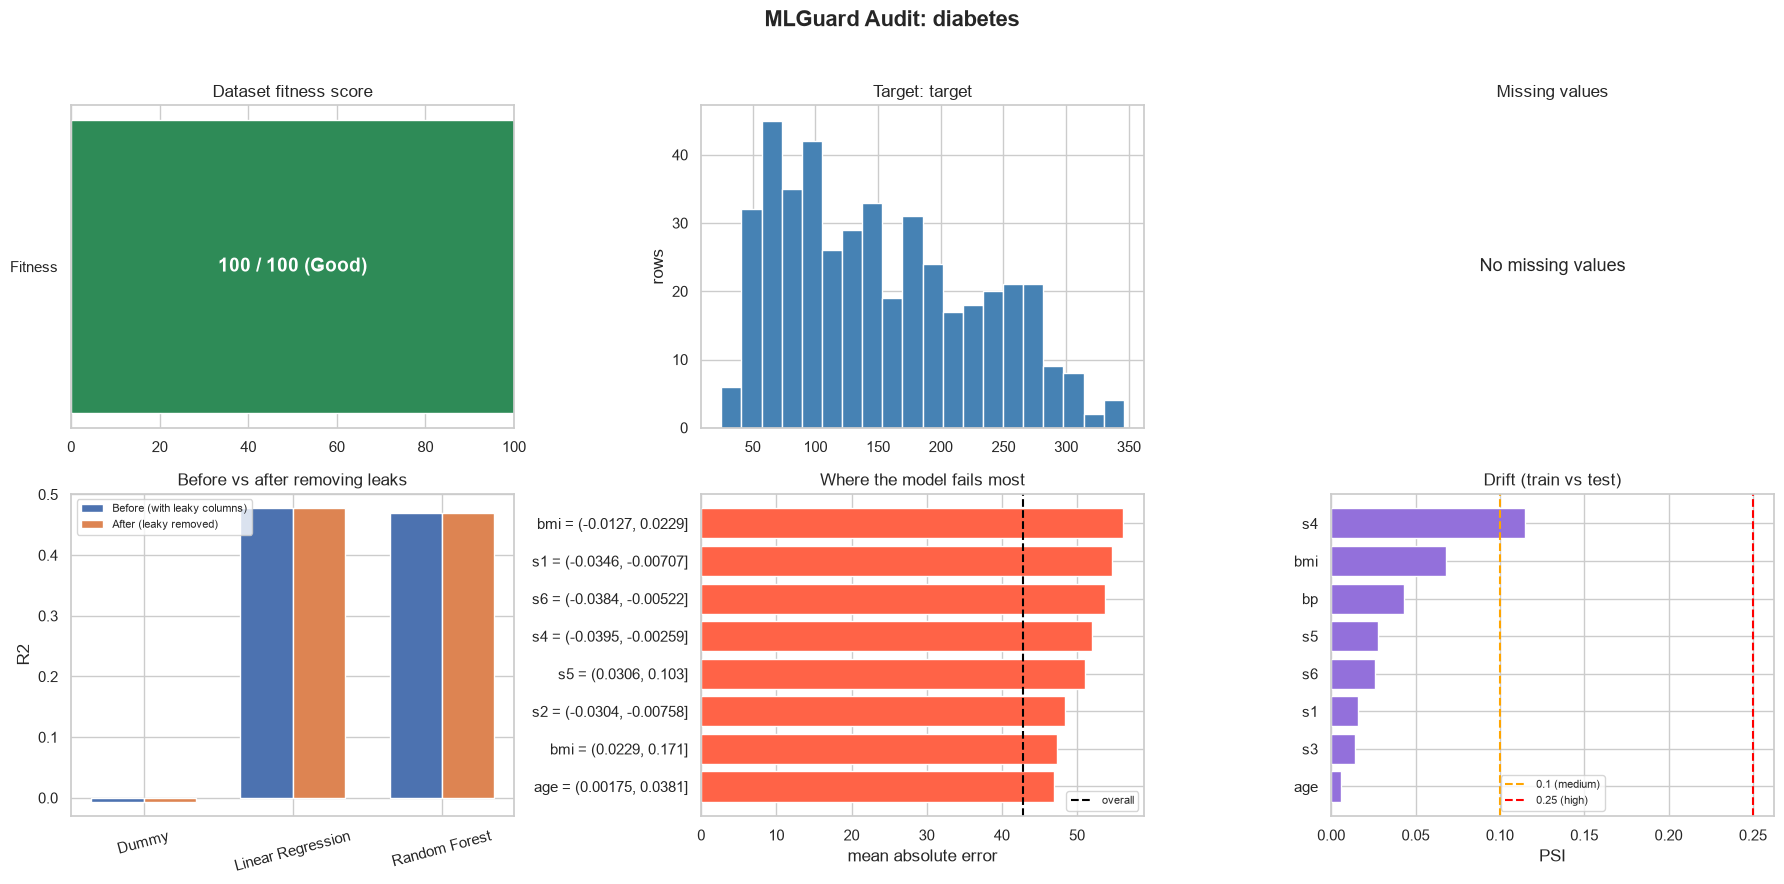

In [89]:
all_results = {}
for name, (data, target) in datasets.items():
    all_results[name] = audit(data, target)
    show_report(all_results[name], name=name, save_dir="../outputs")

In [92]:
# Summary table of all 3 datasets 
rows = []
for name, r in all_results.items():
    comp = r["comparison"]
    metric = "f1" if r["task"] == "Classification" else "R2"
    rf = comp[comp["model"] == "Random Forest"].iloc[0]
    rows.append({"dataset": name, "task": r["task"], "fitness": r["fitness"]["score"],
                 "issues": len(r["findings"]),
                 "leaky_columns": ", ".join(r["before_after"]["leaky_columns"]) or "none",
                 "RF_" + metric + "_before": rf[metric + "_before"],
                 "RF_" + metric + "_after": rf[metric + "_after"]})
pd.DataFrame(rows)

,dataset,task,fitness,issues,leaky_columns,RF_f1_before,RF_f1_after,RF_R2_before,RF_R2_after
0,titanic,Classification,53,10,alive,1.000,0.736,NaN,NaN
1,telco,Classification,85,4,none,0.547,0.547,NaN,NaN
2,diabetes,Regression,100,4,none,NaN,NaN,0.47,0.47


In [91]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
N = 1000
RESULTS = []


def check(name, condition, detail=""):
    RESULTS.append((name, bool(condition), detail))
    print(("PASS" if condition else "FAIL"), "|", name, "|", detail)


def base_regression(n=N):
    df = pd.DataFrame({"a": rng.normal(size=n), "b": rng.normal(size=n), "c": rng.normal(size=n)})
    df["y"] = 3 * df["a"] + 2 * df["b"] + rng.normal(0, 1, n)
    return df


def base_classification(n=N):
    df = pd.DataFrame({"a": rng.normal(size=n), "b": rng.normal(size=n), "c": rng.normal(size=n)})
    score = 1.5 * df["a"] - 1.0 * df["b"] + rng.normal(0, 1, n)
    df["label"] = (score > 0).astype(int)
    return df


# T1: clean regression
df = base_regression()
r = audit(df, "y", run_cv=False)
check("T1 task = Regression", r["task"] == "Regression", r["task"])
check("T1 no leakage flagged", len(r["leakage"]) == 0, str(r["leakage"]))
check("T1 fitness >= 90", r["fitness"]["score"] >= 90, str(r["fitness"]["score"]))
best_r2 = r["comparison"]["R2_after"].max()
check("T1 best R2 > 0.85", best_r2 > 0.85, str(round(best_r2, 3)))

# T2: leaky column
df = base_regression()
df["y_copy"] = df["y"] + rng.normal(0, 0.1, len(df))
r = audit(df, "y", run_cv=False)
check("T2 y_copy flagged", "y_copy" in r["leakage"], str(r["leakage"]))
rf = r["comparison"][r["comparison"]["model"] == "Random Forest"].iloc[0]
check("T2 R2 drops after removing leak", rf["R2_before"] - rf["R2_after"] > 0.03,
      "before=%.3f after=%.3f" % (rf["R2_before"], rf["R2_after"]))
check("T2 fitness loses points", r["fitness"]["score"] <= 80, str(r["fitness"]["score"]))

# T3: ID column
df = base_regression()
df["student_id"] = np.arange(len(df))
r = audit(df, "y", run_cv=False)
check("T3 student_id flagged as ID-like",
      "student_id" in r["leakage"] and r["leakage"]["student_id"][0].startswith("ID-like"), str(r["leakage"]))

# T4: missing values
df = base_regression()
df.loc[rng.choice(len(df), 300, replace=False), "a"] = np.nan
df.loc[rng.choice(len(df), 600, replace=False), "b"] = np.nan
r = audit(df, "y", run_cv=False)
mp = r["quality"]["missing_percent"]
check("T4 a = 30%, b = 60% missing", abs(mp["a"] - 30) < 0.1 and abs(mp["b"] - 60) < 0.1, str(mp))
sev = {f["issue"].split("'")[1]: f["severity"] for f in r["findings"] if f["issue"].startswith("Column '")}
check("T4 b = High, a = Medium", sev.get("b") == "High" and sev.get("a") == "Medium", str(sev))

# T5: duplicates
df = base_regression()
df = pd.concat([df, df.sample(200, random_state=1)], ignore_index=True)
r = audit(df, "y", run_cv=False)
check("T5 200 duplicates found", r["quality"]["duplicates"] == 200, str(r["quality"]["duplicates"]))
check("T5 duplicates severity High", any(f["severity"] == "High" and "duplicate" in f["issue"] for f in r["findings"]))

# T6: class imbalance
df = base_classification()
df["label"] = (rng.random(len(df)) < 0.05).astype(int)
r = audit(df, "label", run_cv=False)
check("T6 task = Classification", r["task"] == "Classification", r["task"])
check("T6 imbalance High", r["imbalance"]["severity"] == "High", str(r["imbalance"]))
base = run_baseline(df, "label", "Classification")
dummy = base[base["model"].str.startswith("Dummy")].iloc[0]
check("T6 Dummy accuracy high but F1 = 0", dummy["accuracy"] > 0.9 and dummy["f1"] == 0,
      "acc=%.3f f1=%.3f" % (dummy["accuracy"], dummy["f1"]))

# T7: numbers stored as text
df = base_regression()
df["c_text"] = df["c"].round(2).astype(str)
r = audit(df, "y", run_cv=False)
check("T7 c_text detected", "c_text" in r["quality"]["wrong_dtypes"], str(r["quality"]["wrong_dtypes"]))

# T8: constant column
df = base_regression()
df["country"] = "India"
r = audit(df, "y", run_cv=False)
check("T8 country detected", "country" in r["quality"]["constant_cols"], str(r["quality"]["constant_cols"]))

# T9: classification leak
df = base_classification()
flip = rng.random(len(df)) < 0.01
df["status_text"] = np.where(df["label"] == 1, "yes", "no")
df.loc[flip, "status_text"] = np.where(df.loc[flip, "label"] == 1, "no", "yes")
r = audit(df, "label", run_cv=False)
check("T9 status_text flagged", "status_text" in r["leakage"], str(r["leakage"]))
rf = r["comparison"][r["comparison"]["model"] == "Random Forest"].iloc[0]
check("T9 F1 drops after removal", rf["f1_before"] - rf["f1_after"] > 0.1,
      "before=%.3f after=%.3f" % (rf["f1_before"], rf["f1_after"]))

# T10: pure noise target
df = base_regression()
df["y"] = rng.normal(size=len(df))
r = audit(df, "y", run_cv=False)
check("T10 best R2 < 0.1", r["comparison"]["R2_after"].max() < 0.1, str(r["comparison"]["R2_after"].max().round(3)))
check("T10 'explains little' finding", any("explains little" in f["issue"] for f in r["findings"]))

# T11: drift
df = base_regression()
ordered = df.sort_values("a")
cut = int(len(ordered) * 0.7)
rep = drift_report(ordered.iloc[:cut], ordered.iloc[cut:], "y")
check("T11 sorted split: a = High", rep.loc[rep["feature"] == "a", "severity"].iloc[0] == "High")
train, test = train_test_split(df, test_size=0.3, random_state=0)
rep = drift_report(train, test, "y")
check("T11 random split: all Low", (rep["severity"] == "Low").all(), str(rep["severity"].tolist()))

# T12: bad input
for label, bad_df, tgt in [("galat target naam", base_regression(), "nahi_hai"),
                           ("sirf 20 rows", base_regression(20), "y")]:
    try:
        audit(bad_df, tgt)
        check("T12 " + label + ": ValueError aana chahiye", False, "error nahi aaya")
    except ValueError as e:
        check("T12 " + label + ": ValueError aaya", True, str(e)[:60])

passed = sum(ok for _, ok, _ in RESULTS)
print("\nTOTAL:", passed, "/", len(RESULTS), "tests pass")

PASS | T1 task = Regression | Regression
PASS | T1 no leakage flagged | {}
PASS | T1 fitness >= 90 | 100
PASS | T1 best R2 > 0.85 | 0.929
PASS | T2 y_copy flagged | {'y_copy': ['correlation with target above 0.9', 'alone predicts the target almost perfectly']}
PASS | T2 R2 drops after removing leak | before=0.999 after=0.916
PASS | T2 fitness loses points | 80
PASS | T3 student_id flagged as ID-like | {'student_id': ['ID-like column (every row is unique)']}
PASS | T4 a = 30%, b = 60% missing | {'a': 30.0, 'b': 60.0}
PASS | T4 b = High, a = Medium | {'b': 'High', 'a': 'Medium'}
PASS | T5 200 duplicates found | 200
PASS | T5 duplicates severity High | 
PASS | T6 task = Classification | Classification
PASS | T6 imbalance High | {'applicable': True, 'class_percent': {0: 95.7, 1: 4.3}, 'minority_percent': 4.3, 'severity': 'High'}
PASS | T6 Dummy accuracy high but F1 = 0 | acc=0.957 f1=0.000
PASS | T7 c_text detected | ['c_text']
PASS | T8 country detected | ['country']
PASS | T9 status_text